# X Education – Lead Scoring Model
### Logistic Regression | Assignment Notebook



---
### Notebook Structure
1. Import Libraries  
2. Load & Inspect Data  
3. Exploratory Data Analysis (EDA)  
4. Data Cleaning & Preprocessing  
5. Feature Engineering  
6. Train-Test Split  
7. Model Building (Logistic Regression with RFE)  
8. Model Evaluation  
9. Lead Score Assignment  
10. Finding Optimal Cutoff  
11. Final Predictions & Business Insights  

## Step 1: Import Libraries

In [1]:
# Standard libraries
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Visualisation
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
%matplotlib inline
sns.set_style('whitegrid')

# Preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Modelling
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE

# Evaluation
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve,
    precision_recall_curve, accuracy_score
)
from statsmodels.stats.outliers_influence import variance_inflation_factor

print('All libraries imported successfully!')

All libraries imported successfully!


## Step 2: Load & Inspect Data



In [ ]:

df = pd.read_csv('Leads.csv')

print(f'Dataset Shape: {df.shape}')
print(f'Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}')
df.head()

Dataset Shape: (9240, 37)
Rows: 9,240  |  Columns: 37


,Prospect ID,Lead Number,Lead Origin,Lead Source,Do Not Email,Do Not Call,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,...,Get updates on DM Content,Lead Profile,City,Asymmetrique Activity Index,Asymmetrique Profile Index,Asymmetrique Activity Score,Asymmetrique Profile Score,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,660737,API,Olark Chat,No,No,0,0.0,0,0.0,...,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Modified
1,2a272436-5132-4136-86fa-dcc88c88f482,660728,API,Organic Search,No,No,0,5.0,674,2.5,...,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Email Opened
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,660727,Landing Page Submission,Direct Traffic,No,No,1,2.0,1532,2.0,...,No,Potential Lead,Mumbai,02.Medium,01.High,14.0,20.0,No,Yes,Email Opened
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,660719,Landing Page Submission,Direct Traffic,No,No,0,1.0,305,1.0,...,No,Select,Mumbai,02.Medium,01.High,13.0,17.0,No,No,Modified
4,3256f628-e534-4826-9d63-4a8b88782852,660681,Landing Page Submission,Google,No,No,1,2.0,1428,1.0,...,No,Select,Mumbai,02.Medium,01.High,15.0,18.0,No,No,Modified


In [ ]:
# Column names
print('Columns:')
for col in df.columns:
    print(' -', col)

Columns:
 - Prospect ID
 - Lead Number
 - Lead Origin
 - Lead Source
 - Do Not Email
 - Do Not Call
 - Converted
 - TotalVisits
 - Total Time Spent on Website
 - Page Views Per Visit
 - Last Activity
 - Country
 - Specialization
 - How did you hear about X Education
 - What is your current occupation
 - What matters most to you in choosing a course
 - Search
 - Magazine
 - Newspaper Article
 - X Education Forums
 - Newspaper
 - Digital Advertisement
 - Through Recommendations
 - Receive More Updates About Our Courses
 - Tags
 - Lead Quality
 - Update me on Supply Chain Content
 - Get updates on DM Content
 - Lead Profile
 - City
 - Asymmetrique Activity Index
 - Asymmetrique Profile Index
 - Asymmetrique Activity Score
 - Asymmetrique Profile Score
 - I agree to pay the amount through cheque
 - A free copy of Mastering The Interview
 - Last Notable Activity


In [ ]:
# Data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9240 entries, 0 to 9239
Data columns (total 37 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   Prospect ID                                    9240 non-null   object 
 1   Lead Number                                    9240 non-null   int64  
 2   Lead Origin                                    9240 non-null   object 
 3   Lead Source                                    9204 non-null   object 
 4   Do Not Email                                   9240 non-null   object 
 5   Do Not Call                                    9240 non-null   object 
 6   Converted                                      9240 non-null   int64  
 7   TotalVisits                                    9103 non-null   float64
 8   Total Time Spent on Website                    9240 non-null   int64  
 9   Page Views Per Visit                           9103 

In [ ]:
# Statistical summary of numeric columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Lead Number,9240.0,617188.435606,23405.995698,579533.0,596484.5,615479.0,637387.25,660737.0
Converted,9240.0,0.385390,0.486714,0.0,0.0,0.0,1.00,1.0
TotalVisits,9103.0,3.445238,4.854853,0.0,1.0,3.0,5.00,251.0
Total Time Spent on Website,9240.0,487.698268,548.021466,0.0,12.0,248.0,936.00,2272.0
Page Views Per Visit,9103.0,2.362820,2.161418,0.0,1.0,2.0,3.00,55.0
Asymmetrique Activity Score,5022.0,14.306252,1.386694,7.0,14.0,14.0,15.00,18.0
Asymmetrique Profile Score,5022.0,16.344883,1.811395,11.0,15.0,16.0,18.00,20.0


In [ ]:
# Target variable distribution
print('Target Variable (Converted) Distribution:')
print(df['Converted'].value_counts())
print(f"\nConversion Rate: {df['Converted'].mean()*100:.2f}%")

Target Variable (Converted) Distribution:
Converted
0    5679
1    3561
Name: count, dtype: int64

Conversion Rate: 38.54%


## Step 3: Exploratory Data Analysis (EDA)

In [ ]:
# ── 3.1 Missing Value Analysis ──────────────────────────────────
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)
print('Columns with Missing Values:')
missing_df

Columns with Missing Values:


,Missing Count,Missing %
Lead Quality,4767,51.590909
Asymmetrique Profile Score,4218,45.649351
Asymmetrique Activity Index,4218,45.649351
Asymmetrique Activity Score,4218,45.649351
Asymmetrique Profile Index,4218,45.649351
Tags,3353,36.287879
What matters most to you in choosing a course,2709,29.318182
Lead Profile,2709,29.318182
What is your current occupation,2690,29.112554
Country,2461,26.634199


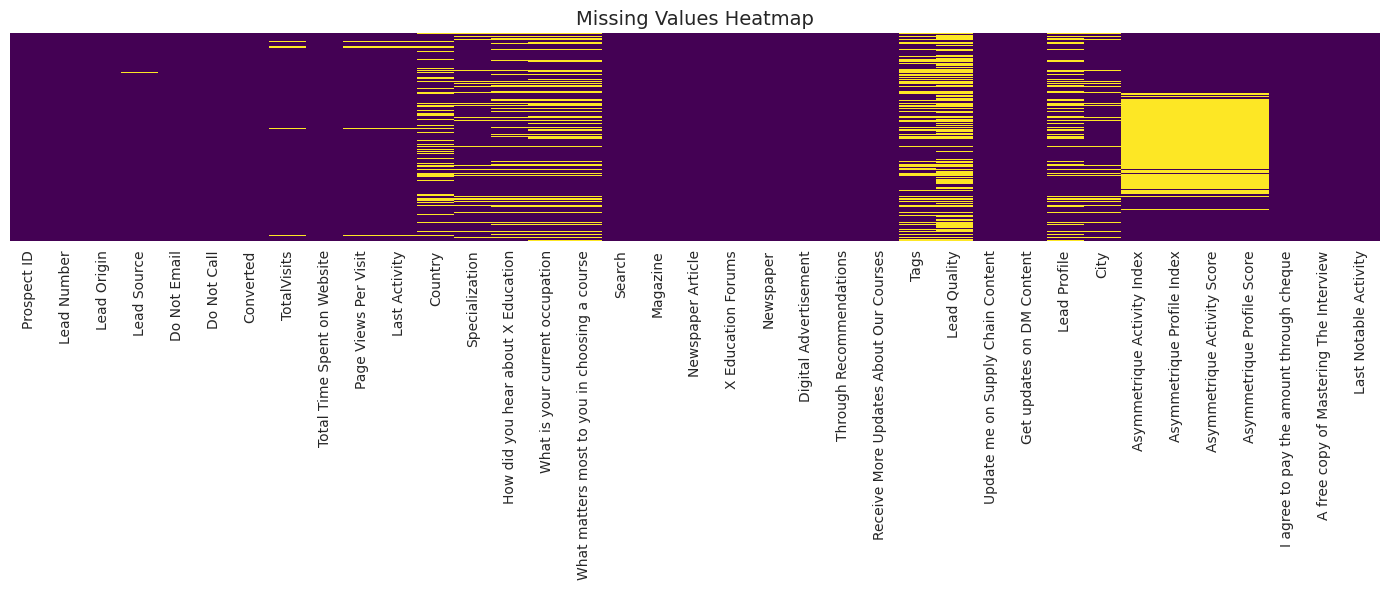

In [ ]:
# Missing value heatmap
plt.figure(figsize=(14, 6))
sns.heatmap(df.isnull(), yticklabels=False, cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap', fontsize=14)
plt.tight_layout()
plt.show()

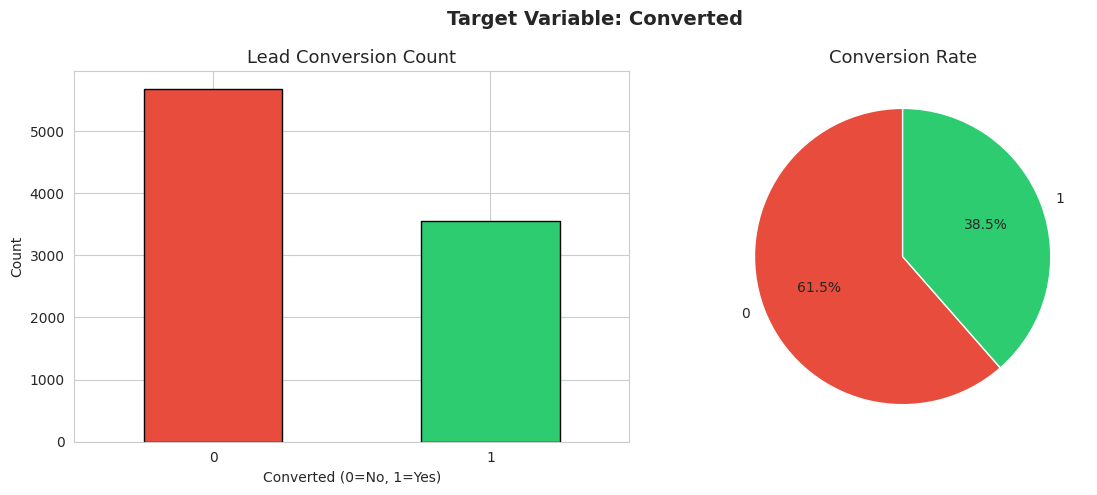

In [ ]:
# ── 3.2 Target Variable Visualisation ───────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Count plot
df['Converted'].value_counts().plot(kind='bar', ax=axes[0], color=['#E74C3C', '#2ECC71'], edgecolor='black')
axes[0].set_title('Lead Conversion Count', fontsize=13)
axes[0].set_xlabel('Converted (0=No, 1=Yes)')
axes[0].set_ylabel('Count')
axes[0].tick_params(rotation=0)

# Pie chart
df['Converted'].value_counts().plot(kind='pie', ax=axes[1], autopct='%1.1f%%',
                                     colors=['#E74C3C', '#2ECC71'], startangle=90)
axes[1].set_title('Conversion Rate', fontsize=13)
axes[1].set_ylabel('')

plt.suptitle('Target Variable: Converted', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Numeric columns: ['Lead Number', 'TotalVisits', 'Total Time Spent on Website', 'Page Views Per Visit', 'Asymmetrique Activity Score', 'Asymmetrique Profile Score']


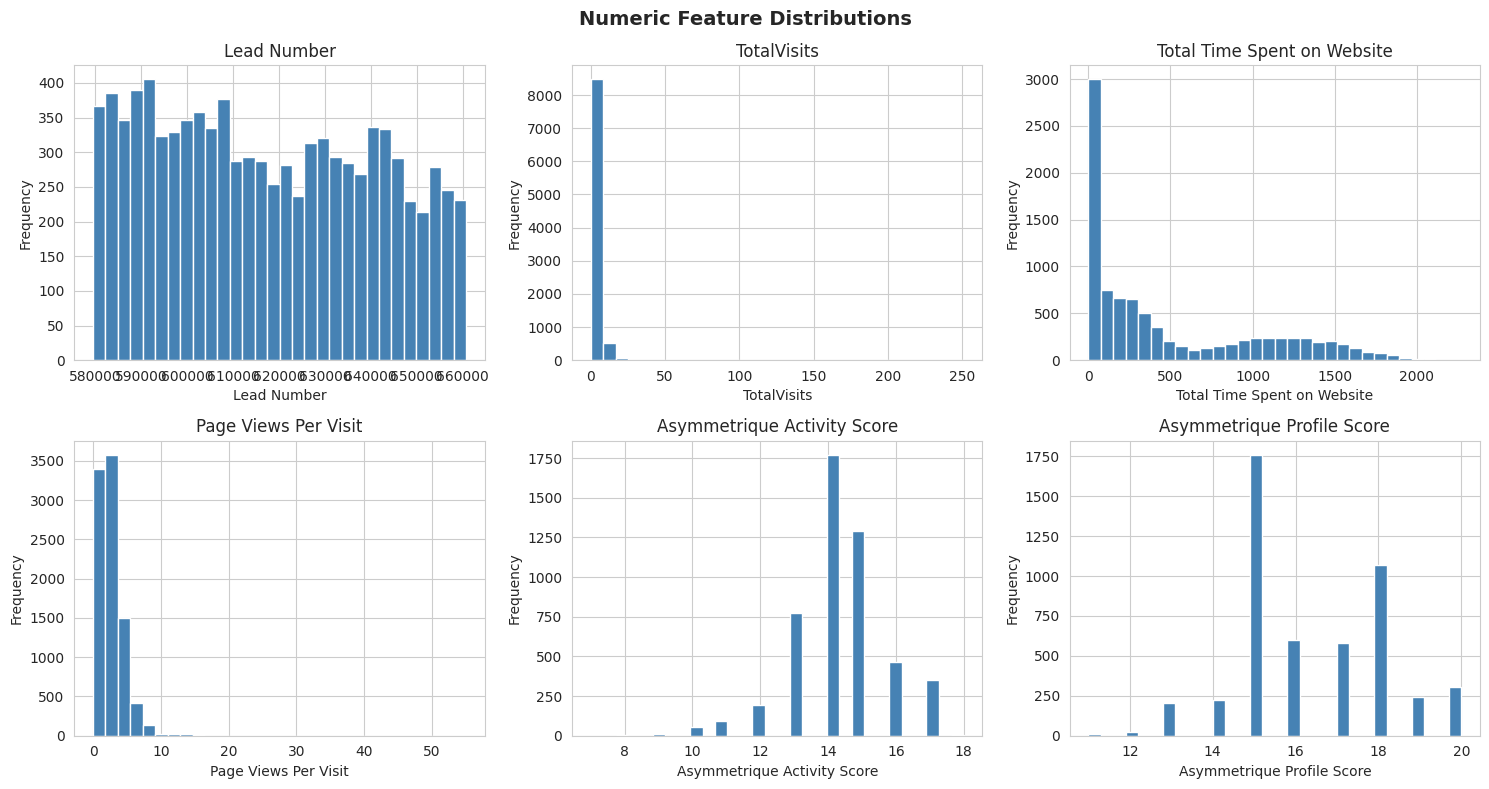

In [ ]:
# ── 3.3 Numeric Features Distribution ───────────────────────────
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
num_cols = [c for c in num_cols if c != 'Converted']
print('Numeric columns:', num_cols)

n = len(num_cols)
ncols = 3
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(15, nrows * 4))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    df[col].hist(ax=axes[i], bins=30, color='steelblue', edgecolor='white')
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Numeric Feature Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

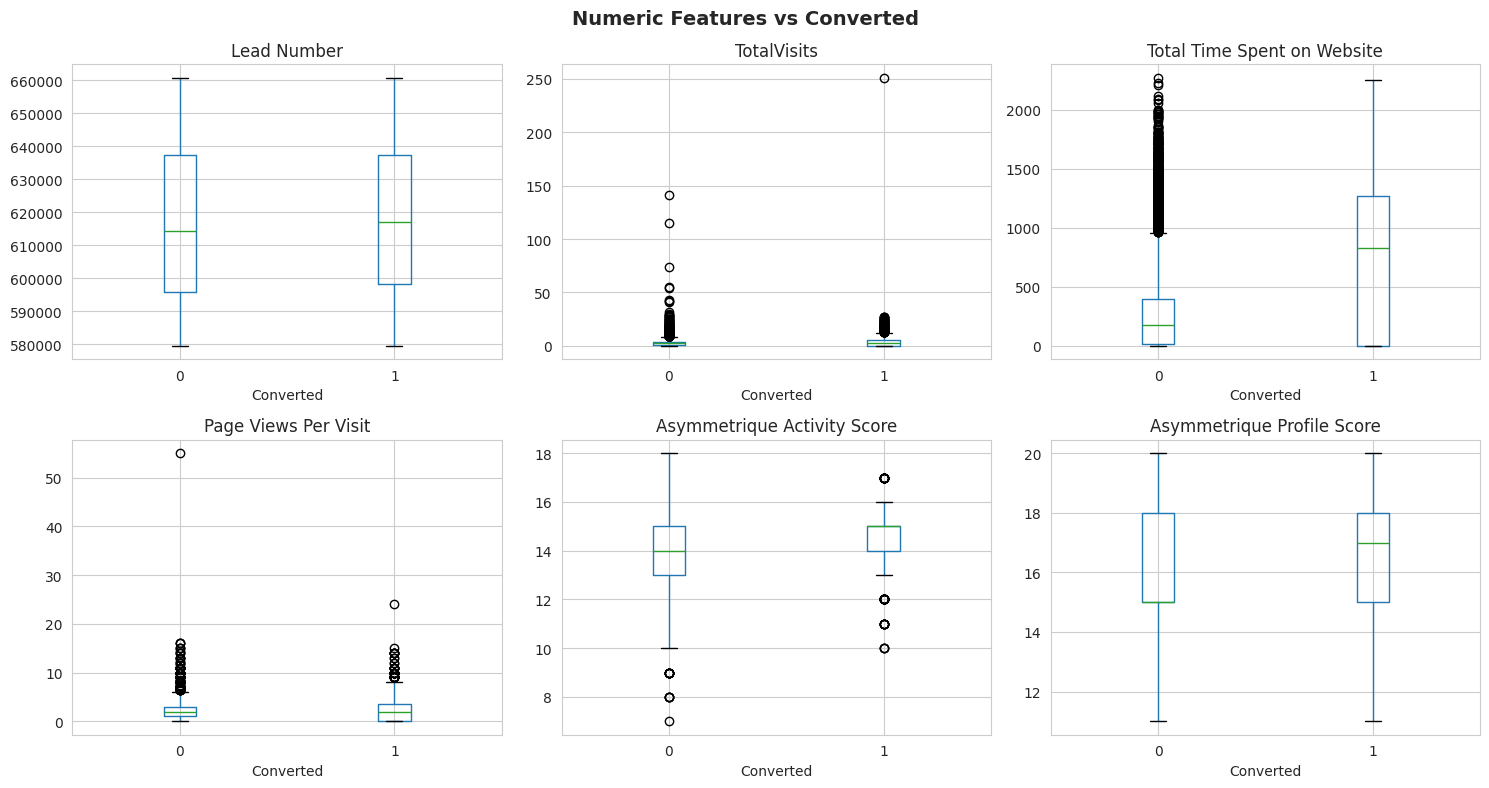

In [ ]:
# ── 3.4 Numeric Features vs Converted (Box Plots) ───────────────
fig, axes = plt.subplots(nrows, ncols, figsize=(15, nrows * 4))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    df.boxplot(column=col, by='Converted', ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('Converted')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Numeric Features vs Converted', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# ── 3.5 Categorical Features Analysis ───────────────────────────
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f'Categorical columns ({len(cat_cols)}):', cat_cols)

Categorical columns (30): ['Prospect ID', 'Lead Origin', 'Lead Source', 'Do Not Email', 'Do Not Call', 'Last Activity', 'Country', 'Specialization', 'How did you hear about X Education', 'What is your current occupation', 'What matters most to you in choosing a course', 'Search', 'Magazine', 'Newspaper Article', 'X Education Forums', 'Newspaper', 'Digital Advertisement', 'Through Recommendations', 'Receive More Updates About Our Courses', 'Tags', 'Lead Quality', 'Update me on Supply Chain Content', 'Get updates on DM Content', 'Lead Profile', 'City', 'Asymmetrique Activity Index', 'Asymmetrique Profile Index', 'I agree to pay the amount through cheque', 'A free copy of Mastering The Interview', 'Last Notable Activity']


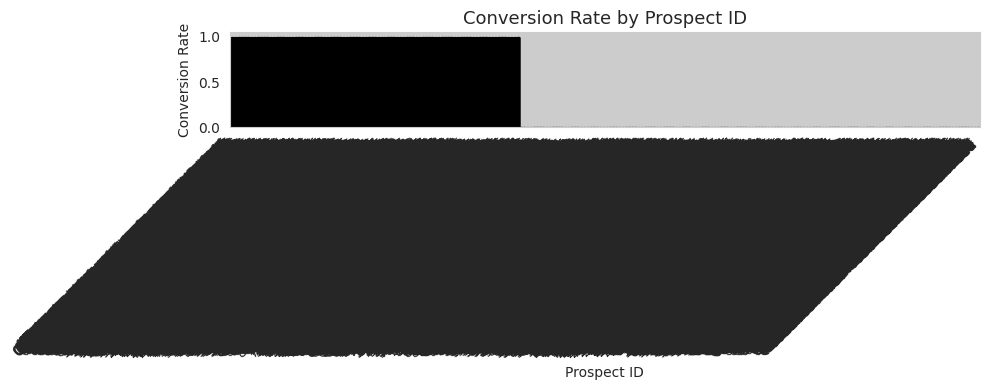

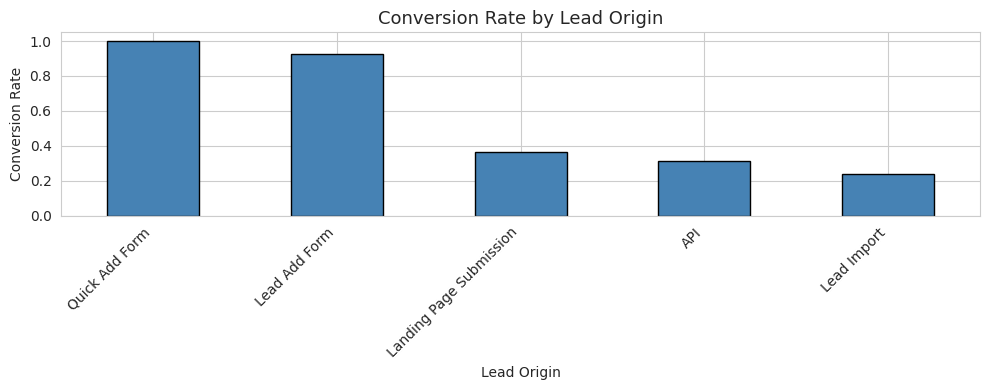

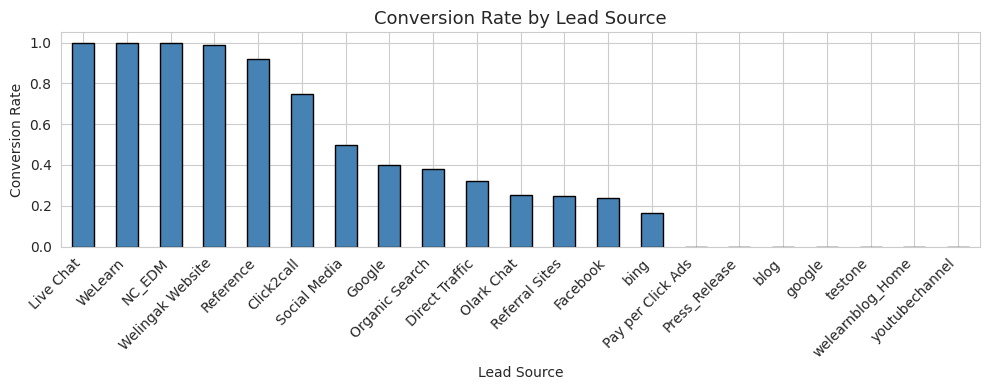

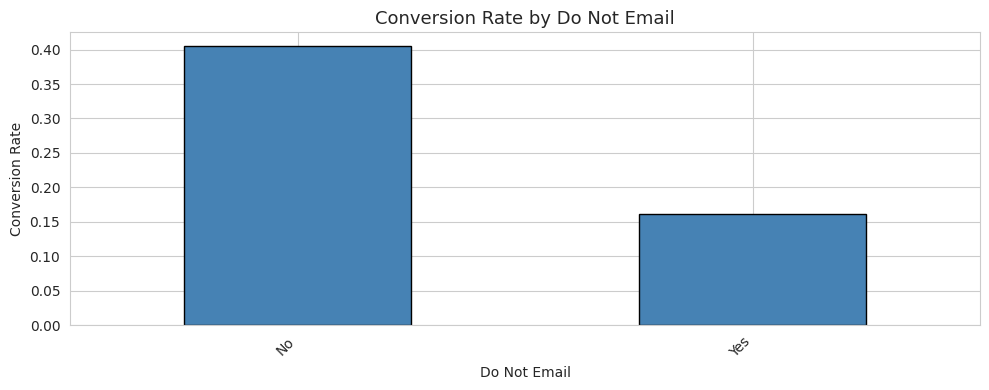

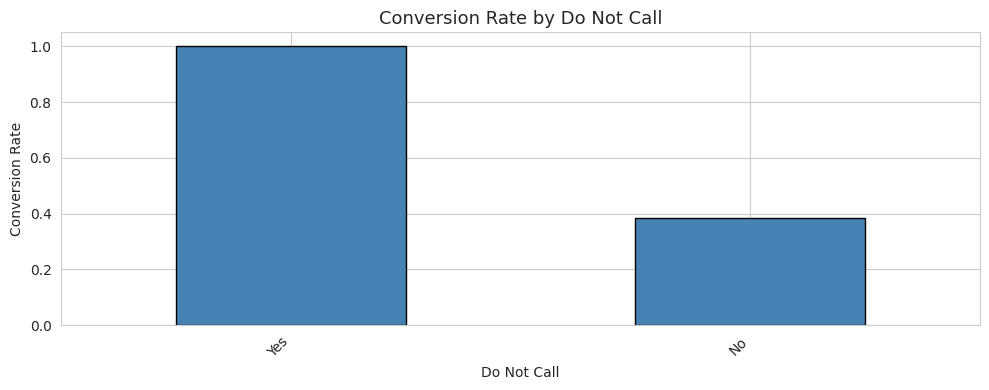

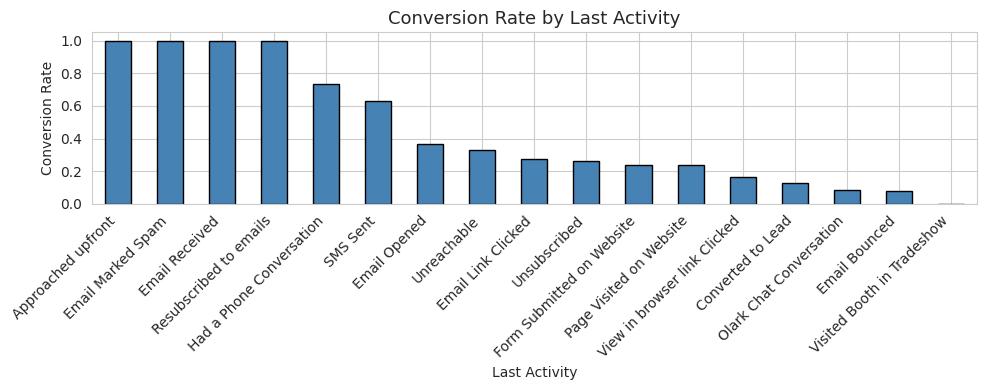

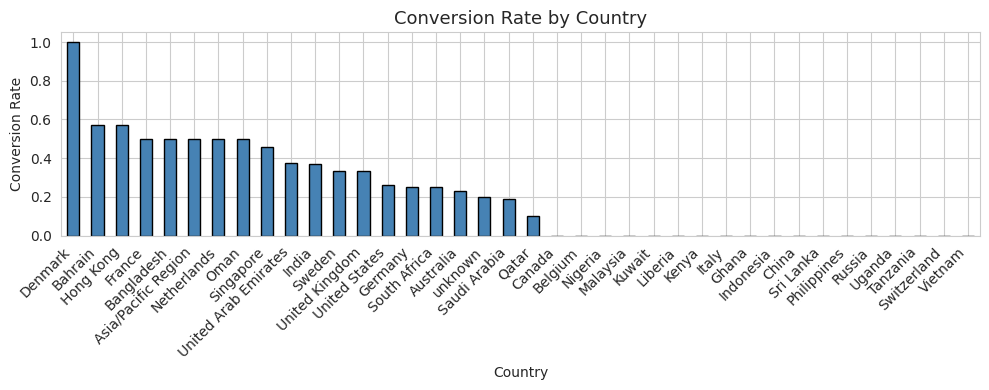

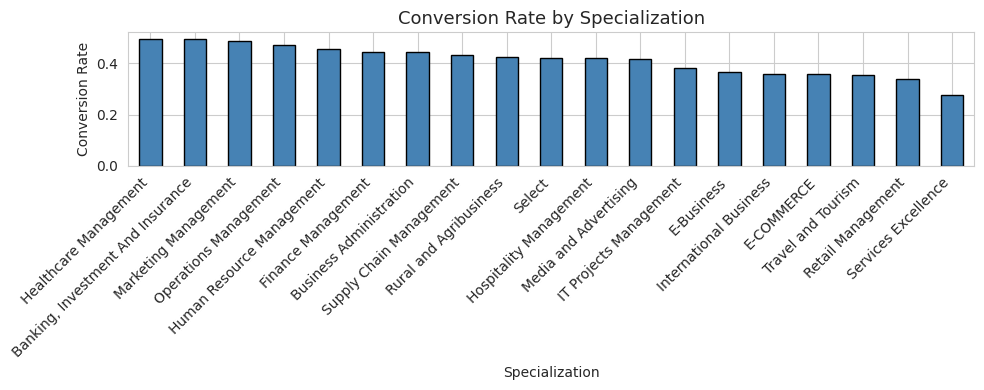

In [ ]:
# Conversion rate by each categorical feature
for col in cat_cols[:8]:   # show first 8; remove slice to see all
    plt.figure(figsize=(10, 4))
    conv_rate = df.groupby(col)['Converted'].mean().sort_values(ascending=False)
    conv_rate.plot(kind='bar', color='steelblue', edgecolor='black')
    plt.title(f'Conversion Rate by {col}', fontsize=13)
    plt.ylabel('Conversion Rate')
    plt.xlabel(col)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

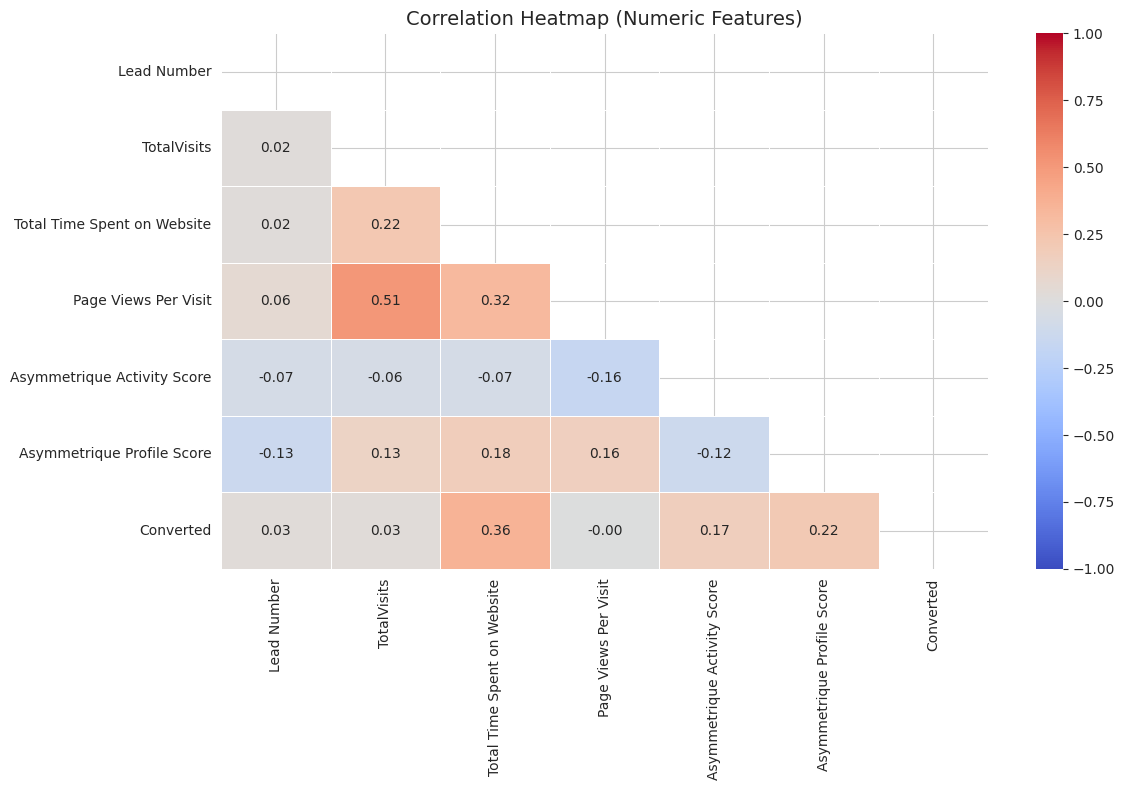

In [ ]:
# ── 3.6 Correlation Heatmap ──────────────────────────────────────
plt.figure(figsize=(12, 8))
corr = df[num_cols + ['Converted']].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap (Numeric Features)', fontsize=14)
plt.tight_layout()
plt.show()

## Step 4: Data Cleaning & Preprocessing

In [ ]:
# ── 4.1 Replace 'Select' with NaN ────────────────────────────────
# 'Select' is treated like a null value — the user didn't choose anything meaningful
df.replace('Select', np.nan, inplace=True)
print("Replaced 'Select' with NaN.")

Replaced 'Select' with NaN.


In [ ]:
# ── 4.2 Drop columns with > 40% missing values ───────────────────
threshold = 0.40
missing_pct_updated = df.isnull().mean()
cols_to_drop = missing_pct_updated[missing_pct_updated > threshold].index.tolist()
print(f'Columns dropped (>{threshold*100}% missing): {cols_to_drop}')
df.drop(columns=cols_to_drop, inplace=True)

Columns dropped (>40.0% missing): ['How did you hear about X Education', 'Lead Quality', 'Lead Profile', 'Asymmetrique Activity Index', 'Asymmetrique Profile Index', 'Asymmetrique Activity Score', 'Asymmetrique Profile Score']


In [ ]:
# ── 4.3 Drop irrelevant / ID columns ────────────────────────────
# These columns don't contribute to prediction
id_cols = ['Prospect ID', 'Lead Number']
id_cols_present = [c for c in id_cols if c in df.columns]
df.drop(columns=id_cols_present, inplace=True)
print(f'Dropped ID columns: {id_cols_present}')

Dropped ID columns: ['Prospect ID', 'Lead Number']


In [ ]:
# ── 4.4 Drop near-constant columns (one value > 95% of data) ────
const_cols = []
for col in df.columns:
    top_freq = df[col].value_counts(normalize=True, dropna=False).iloc[0]
    if top_freq > 0.95:
        const_cols.append(col)

print(f'Near-constant columns to drop: {const_cols}')
df.drop(columns=const_cols, inplace=True)

Near-constant columns to drop: ['Do Not Call', 'Search', 'Magazine', 'Newspaper Article', 'X Education Forums', 'Newspaper', 'Digital Advertisement', 'Through Recommendations', 'Receive More Updates About Our Courses', 'Update me on Supply Chain Content', 'Get updates on DM Content', 'I agree to pay the amount through cheque']


In [ ]:
# ── 4.5 Handle Remaining Missing Values ─────────────────────────
# Categorical: fill with mode
cat_cols_current = df.select_dtypes(include='object').columns
for col in cat_cols_current:
    df[col].fillna(df[col].mode()[0], inplace=True)

# Numeric: fill with median
num_cols_current = df.select_dtypes(include=['int64', 'float64']).columns
num_cols_current = [c for c in num_cols_current if c != 'Converted']
for col in num_cols_current:
    df[col].fillna(df[col].median(), inplace=True)

print(f'Remaining nulls: {df.isnull().sum().sum()}')
print(f'Dataset shape after cleaning: {df.shape}')

Remaining nulls: 0
Dataset shape after cleaning: (9240, 16)


## Step 5: Feature Engineering – Dummy Variable Creation

In [ ]:
# ── 5.1 Create dummy variables for categorical features ──────────
cat_cols_current = df.select_dtypes(include='object').columns.tolist()
print(f'Categorical columns to encode ({len(cat_cols_current)}): {cat_cols_current}')

Categorical columns to encode (12): ['Lead Origin', 'Lead Source', 'Do Not Email', 'Last Activity', 'Country', 'Specialization', 'What is your current occupation', 'What matters most to you in choosing a course', 'Tags', 'City', 'A free copy of Mastering The Interview', 'Last Notable Activity']


In [ ]:
# For each categorical column, keep only top N categories to avoid high cardinality
# (merge rare categories into 'Other')
TOP_N = 7
for col in cat_cols_current:
    top_cats = df[col].value_counts().nlargest(TOP_N).index
    df[col] = df[col].apply(lambda x: x if x in top_cats else 'Other')

# One-hot encode
df_encoded = pd.get_dummies(df, columns=cat_cols_current, drop_first=True)
print(f'Shape after encoding: {df_encoded.shape}')
df_encoded.head(3)

Shape after encoding: (9240, 64)


,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,Lead Origin_Landing Page Submission,Lead Origin_Lead Add Form,Lead Origin_Lead Import,Lead Origin_Quick Add Form,Lead Source_Google,Lead Source_Olark Chat,...,City_Thane & Outskirts,City_Tier II Cities,A free copy of Mastering The Interview_Yes,Last Notable Activity_Email Link Clicked,Last Notable Activity_Email Opened,Last Notable Activity_Modified,Last Notable Activity_Olark Chat Conversation,Last Notable Activity_Other,Last Notable Activity_Page Visited on Website,Last Notable Activity_SMS Sent
0,0,0.0,0,0.0,False,False,False,False,False,True,...,False,False,False,False,False,True,False,False,False,False
1,0,5.0,674,2.5,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
2,1,2.0,1532,2.0,True,False,False,False,False,False,...,False,False,True,False,True,False,False,False,False,False


## Step 6: Train-Test Split

In [ ]:
# Separate features and target
X = df_encoded.drop('Converted', axis=1)
y = df_encoded['Converted']

# 70-30 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print(f'Train size : {X_train.shape[0]:,} rows')
print(f'Test size  : {X_test.shape[0]:,} rows')
print(f'Train conversion rate: {y_train.mean()*100:.2f}%')
print(f'Test  conversion rate: {y_test.mean()*100:.2f}%')

Train size : 6,468 rows
Test size  : 2,772 rows
Train conversion rate: 38.54%
Test  conversion rate: 38.53%


In [ ]:
# Feature Scaling
scaler = StandardScaler()

num_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

X_train[num_features] = scaler.fit_transform(X_train[num_features])
X_test[num_features]  = scaler.transform(X_test[num_features])

print('Scaling complete.')

Scaling complete.


## Step 7: Model Building
### 7.1 Feature Selection with RFE

In [ ]:
# ── 7.1 RFE to select top 15 features ───────────────────────────
logreg_rfe = LogisticRegression(max_iter=1000, random_state=42)
rfe = RFE(estimator=logreg_rfe, n_features_to_select=15)
rfe.fit(X_train, y_train)

rfe_support = pd.Series(rfe.support_, index=X_train.columns)
selected_features = rfe_support[rfe_support].index.tolist()

print(f'Features selected by RFE ({len(selected_features)}):')
for f in selected_features:
    print(' -', f)

Features selected by RFE (15):
 - Total Time Spent on Website
 - Lead Origin_Lead Add Form
 - Lead Source_Welingak Website
 - Do Not Email_Yes
 - Last Activity_Olark Chat Conversation
 - Country_Saudi Arabia
 - What is your current occupation_Working Professional
 - Tags_Busy
 - Tags_Closed by Horizzon
 - Tags_Other
 - Tags_Ringing
 - Tags_Will revert after reading the email
 - Tags_switched off
 - Last Notable Activity_Other
 - Last Notable Activity_SMS Sent


### 7.2 Statsmodels Logistic Regression (for p-values & VIF)

In [ ]:
def get_vif(df_features):
    """Calculate VIF for multicollinearity check."""
    vif_data = pd.DataFrame()
    vif_data['Feature'] = df_features.columns
    vif_data['VIF'] = [variance_inflation_factor(df_features.values, i)
                       for i in range(df_features.shape[1])]
    return vif_data.sort_values('VIF', ascending=False)


def build_logit_model(features, X_tr, y_tr):
    """Fit a statsmodels logistic regression."""
    X_tr_sm = sm.add_constant(X_tr[features])
    model = sm.Logit(y_tr, X_tr_sm).fit(disp=0)
    return model

In [ ]:
model1 = build_logit_model(selected_features, X_train[selected_features].astype(int), y_train)
print(model1.summary2())

                                           Results: Logit
Model:                           Logit                        Method:                       MLE      
Dependent Variable:              Converted                    Pseudo R-squared:             0.522    
Date:                            2026-06-24 07:46             AIC:                          4154.3737
No. Observations:                6468                         BIC:                          4262.7677
Df Model:                        15                           Log-Likelihood:               -2061.2  
Df Residuals:                    6452                         LL-Null:                      -4312.0  
Converged:                       1.0000                       LLR p-value:                  0.0000   
No. Iterations:                  10.0000                      Scale:                        1.0000   
-----------------------------------------------------------------------------------------------------
                        

In [ ]:
# ── VIF check ────────────────────────────────────────────────────
vif_df = get_vif(X_train[selected_features].astype(int))
print('VIF Values:')
print(vif_df.to_string(index=False))

VIF Values:
                                             Feature      VIF
            Tags_Will revert after reading the email 1.777219
                           Lead Origin_Lead Add Form 1.658037
                      Last Notable Activity_SMS Sent 1.521048
                         Total Time Spent on Website 1.298138
                        Lead Source_Welingak Website 1.283310
                             Tags_Closed by Horizzon 1.280510
What is your current occupation_Working Professional 1.216992
               Last Activity_Olark Chat Conversation 1.135322
                                    Do Not Email_Yes 1.119908
                                        Tags_Ringing 1.101027
                                          Tags_Other 1.068230
                         Last Notable Activity_Other 1.044540
                                           Tags_Busy 1.040747
                                   Tags_switched off 1.028621
                                Country_Saudi Arabia 1.003

In [ ]:
# ── Iteratively drop features with high p-value (>0.05) or VIF (>5) ─
# NOTE: Run this cell repeatedly after reviewing summary until model is stable

# After reviewing, list features to drop here:
features_to_drop = ['Tags_Ringing', 'Tags_switched off', 'Country_Saudi Arabia']  # e.g. ['Feature_X', 'Feature_Y']

final_features = [f for f in selected_features if f not in features_to_drop]
print(f'Final feature count: {len(final_features)}')

final_model = build_logit_model(final_features, X_train[final_features].astype(int), y_train)
print(final_model.summary2())

Final feature count: 12
                                           Results: Logit
Model:                           Logit                        Method:                       MLE      
Dependent Variable:              Converted                    Pseudo R-squared:             0.521    
Date:                            2026-06-24 07:48             AIC:                          4155.7362
No. Observations:                6468                         BIC:                          4243.8063
Df Model:                        12                           Log-Likelihood:               -2064.9  
Df Residuals:                    6455                         LL-Null:                      -4312.0  
Converged:                       1.0000                       LLR p-value:                  0.0000   
No. Iterations:                  10.0000                      Scale:                        1.0000   
-----------------------------------------------------------------------------------------------------


In [ ]:
# Final VIF check
vif_final = get_vif(X_train[final_features].astype(int))
print('Final VIF Values:')
print(vif_final.to_string(index=False))

Final VIF Values:
                                             Feature      VIF
            Tags_Will revert after reading the email 1.715467
                           Lead Origin_Lead Add Form 1.656949
                      Last Notable Activity_SMS Sent 1.393078
                         Total Time Spent on Website 1.285595
                        Lead Source_Welingak Website 1.282721
                             Tags_Closed by Horizzon 1.280055
What is your current occupation_Working Professional 1.215262
               Last Activity_Olark Chat Conversation 1.124720
                                    Do Not Email_Yes 1.106096
                                          Tags_Other 1.063859
                         Last Notable Activity_Other 1.042868
                                           Tags_Busy 1.035690


## Step 8: Model Evaluation
### 8.1 Predictions on Train Set

In [ ]:
# Train set predictions
X_train_sm = sm.add_constant(X_train[final_features].astype(int))
y_train_pred_prob = final_model.predict(X_train_sm)

# Default threshold = 0.5
y_train_pred = (y_train_pred_prob >= 0.5).astype(int)

print('Train Set Evaluation (threshold = 0.5):')
print(f'Accuracy  : {accuracy_score(y_train, y_train_pred)*100:.2f}%')
print()
print(classification_report(y_train, y_train_pred))

Train Set Evaluation (threshold = 0.5):
Accuracy  : 87.03%

              precision    recall  f1-score   support

           0       0.87      0.93      0.90      3975
           1       0.87      0.78      0.82      2493

    accuracy                           0.87      6468
   macro avg       0.87      0.85      0.86      6468
weighted avg       0.87      0.87      0.87      6468



### 8.2 ROC Curve & AUC

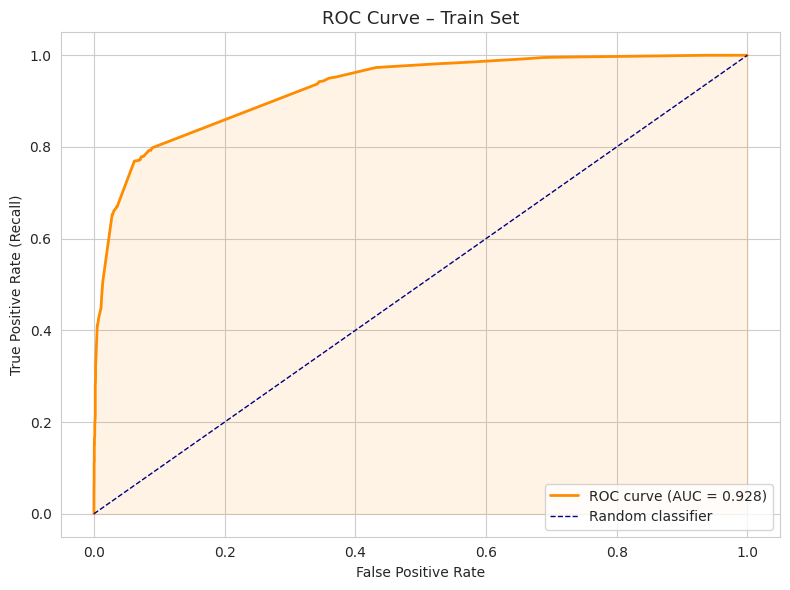

AUC Score: 0.9278


In [ ]:
fpr, tpr, thresholds = roc_curve(y_train, y_train_pred_prob)
auc_score = roc_auc_score(y_train, y_train_pred_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Random classifier')
plt.fill_between(fpr, tpr, alpha=0.1, color='darkorange')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve – Train Set', fontsize=13)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f'AUC Score: {auc_score:.4f}')

### 8.3 Finding Optimal Probability Cutoff

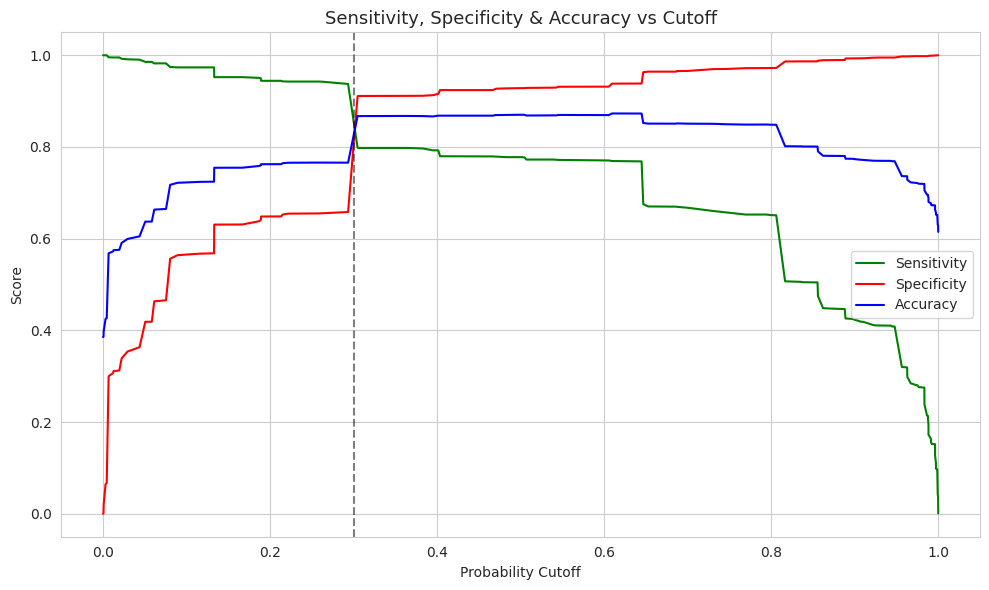

In [ ]:
# Sensitivity, Specificity, Accuracy across cutoffs
cutoff_df = pd.DataFrame({'Probability': thresholds})

sensitivities, specificities, accuracies = [], [], []

for cut in thresholds:
    preds = (y_train_pred_prob >= cut).astype(int)
    cm = confusion_matrix(y_train, preds)
    tn, fp, fn, tp = cm.ravel() if cm.shape == (2, 2) else (0, 0, 0, 0)
    sensitivities.append(tp / (tp + fn + 1e-9))
    specificities.append(tn / (tn + fp + 1e-9))
    accuracies.append((tp + tn) / (tp + tn + fp + fn + 1e-9))

cutoff_df['Sensitivity'] = sensitivities
cutoff_df['Specificity'] = specificities
cutoff_df['Accuracy']    = accuracies

# Plot
plt.figure(figsize=(10, 6))
plt.plot(cutoff_df['Probability'], cutoff_df['Sensitivity'], label='Sensitivity', color='green')
plt.plot(cutoff_df['Probability'], cutoff_df['Specificity'], label='Specificity', color='red')
plt.plot(cutoff_df['Probability'], cutoff_df['Accuracy'],    label='Accuracy',    color='blue')
plt.xlabel('Probability Cutoff')
plt.ylabel('Score')
plt.title('Sensitivity, Specificity & Accuracy vs Cutoff', fontsize=13)
plt.legend()
plt.axvline(x=0.3, color='black', linestyle='--', alpha=0.5, label='cutoff=0.3')
plt.tight_layout()
plt.show()

--- Train Set at Cutoff = 0.3 ---
Accuracy   : 86.73%
Sensitivity: 79.82%
Specificity: 91.07%
Precision  : 84.86%


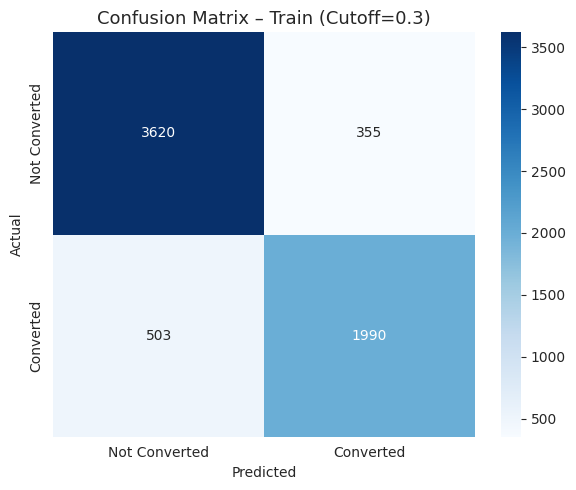

In [ ]:
# ── Choose optimal cutoff ─────────────────────────────────────────
# Adjust this value based on the plot above; ~0.3 often balances sensitivity
OPTIMAL_CUTOFF = 0.30

y_train_pred_opt = (y_train_pred_prob >= OPTIMAL_CUTOFF).astype(int)

cm_train = confusion_matrix(y_train, y_train_pred_opt)
tn, fp, fn, tp = cm_train.ravel()

print(f'--- Train Set at Cutoff = {OPTIMAL_CUTOFF} ---')
print(f'Accuracy   : {(tp+tn)/(tp+tn+fp+fn)*100:.2f}%')
print(f'Sensitivity: {tp/(tp+fn)*100:.2f}%')
print(f'Specificity: {tn/(tn+fp)*100:.2f}%')
print(f'Precision  : {tp/(tp+fp)*100:.2f}%')

# Confusion matrix heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Converted', 'Converted'],
            yticklabels=['Not Converted', 'Converted'])
plt.title(f'Confusion Matrix – Train (Cutoff={OPTIMAL_CUTOFF})', fontsize=13)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

### 8.4 Precision-Recall Curve

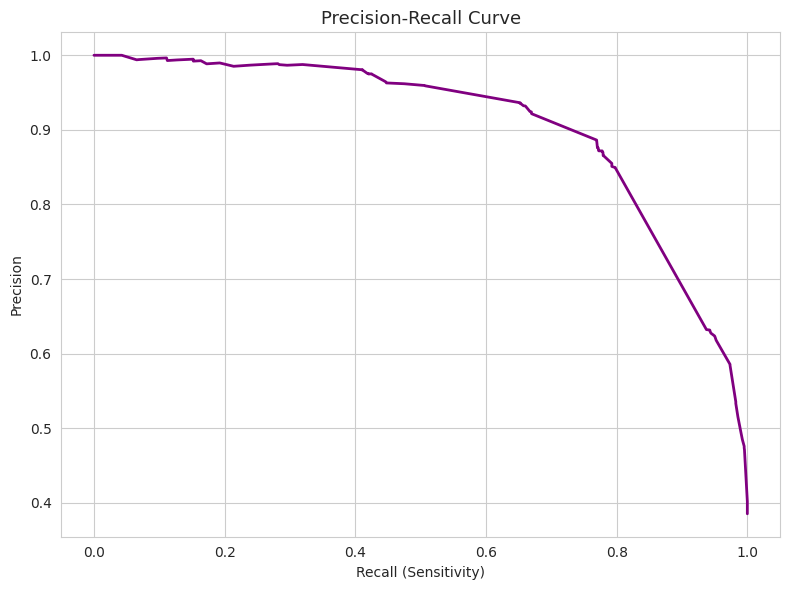

In [ ]:
precision, recall, pr_thresholds = precision_recall_curve(y_train, y_train_pred_prob)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, color='purple', lw=2)
plt.xlabel('Recall (Sensitivity)')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve', fontsize=13)
plt.tight_layout()
plt.show()

## Step 9: Lead Score Assignment

Train Lead Score Distribution:
count    6468.000000
mean       38.427180
std        36.962405
min         0.000000
25%         4.000000
50%        29.000000
75%        81.000000
max       100.000000
Name: Lead_Score, dtype: float64


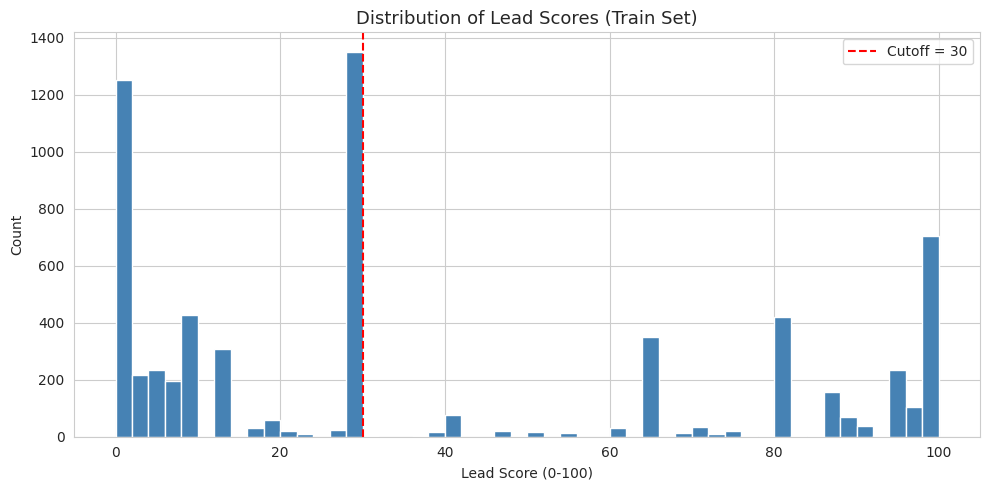

In [ ]:
# ── 9.1 Assign Lead Score (0–100) to the TRAIN set ───────────────
# Lead Score = predicted probability × 100
train_results = X_train[final_features].copy()
train_results['Converted_Actual']   = y_train.values
train_results['Conversion_Prob']    = y_train_pred_prob.values
train_results['Lead_Score']         = (y_train_pred_prob * 100).round(0).astype(int)
train_results['Predicted_Converted'] = y_train_pred_opt

print('Train Lead Score Distribution:')
print(train_results['Lead_Score'].describe())

# Distribution of Lead Scores
plt.figure(figsize=(10, 5))
train_results['Lead_Score'].hist(bins=50, color='steelblue', edgecolor='white')
plt.axvline(x=OPTIMAL_CUTOFF*100, color='red', linestyle='--', label=f'Cutoff = {OPTIMAL_CUTOFF*100:.0f}')
plt.title('Distribution of Lead Scores (Train Set)', fontsize=13)
plt.xlabel('Lead Score (0-100)')
plt.ylabel('Count')
plt.legend()
plt.tight_layout()
plt.show()

## Step 10: Final Evaluation on Test Set

In [ ]:
# ── 10.1 Test set predictions ─────────────────────────────────────
X_test_sm = sm.add_constant(X_test[final_features].astype(int))
y_test_pred_prob = final_model.predict(X_test_sm)
y_test_pred_opt  = (y_test_pred_prob >= OPTIMAL_CUTOFF).astype(int)

cm_test = confusion_matrix(y_test, y_test_pred_opt)
tn_t, fp_t, fn_t, tp_t = cm_test.ravel()

print(f'--- TEST SET at Cutoff = {OPTIMAL_CUTOFF} ---')
print(f'Accuracy   : {(tp_t+tn_t)/(tp_t+tn_t+fp_t+fn_t)*100:.2f}%')
print(f'Sensitivity: {tp_t/(tp_t+fn_t)*100:.2f}%')
print(f'Specificity: {tn_t/(tn_t+fp_t)*100:.2f}%')
print(f'Precision  : {tp_t/(tp_t+fp_t)*100:.2f}%')
print()
print('Classification Report:')
print(classification_report(y_test, y_test_pred_opt))

--- TEST SET at Cutoff = 0.3 ---
Accuracy   : 85.79%
Sensitivity: 78.56%
Specificity: 90.32%
Precision  : 83.57%

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.90      0.89      1704
           1       0.84      0.79      0.81      1068

    accuracy                           0.86      2772
   macro avg       0.85      0.84      0.85      2772
weighted avg       0.86      0.86      0.86      2772



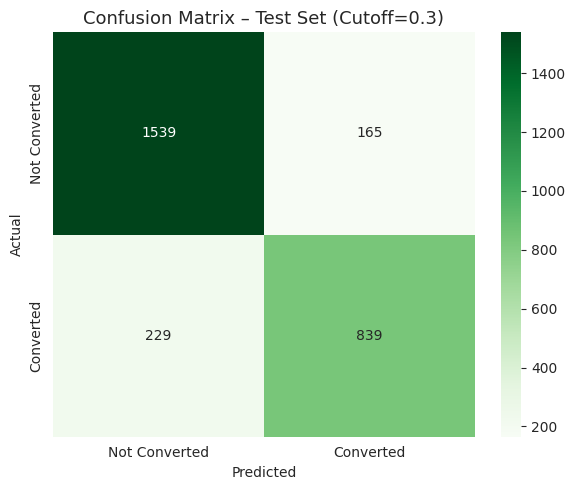

In [ ]:
# Confusion matrix – Test
plt.figure(figsize=(6, 5))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Not Converted', 'Converted'],
            yticklabels=['Not Converted', 'Converted'])
plt.title(f'Confusion Matrix – Test Set (Cutoff={OPTIMAL_CUTOFF})', fontsize=13)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

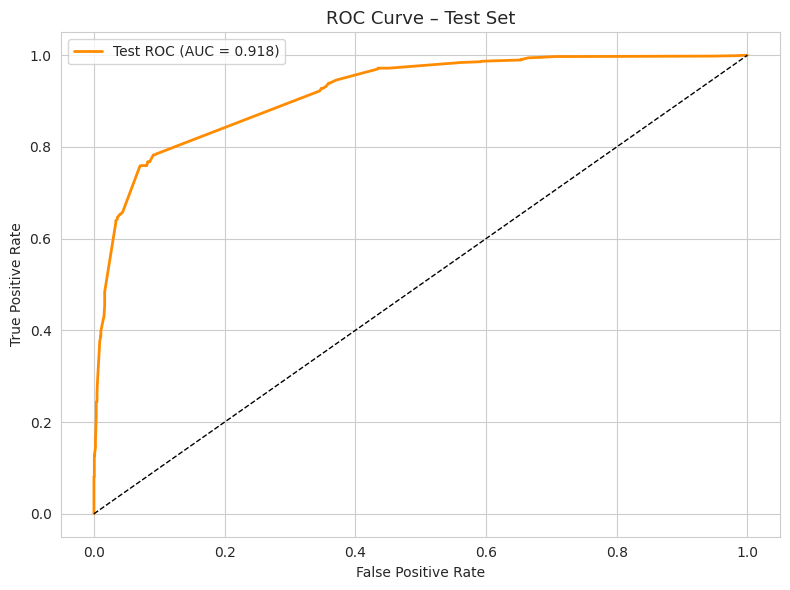

In [ ]:
# AUC on Test
auc_test = roc_auc_score(y_test, y_test_pred_prob)
fpr_t, tpr_t, _ = roc_curve(y_test, y_test_pred_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr_t, tpr_t, color='darkorange', lw=2, label=f'Test ROC (AUC = {auc_test:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – Test Set', fontsize=13)
plt.legend()
plt.tight_layout()
plt.show()

## Step 11: Lead Scores on Test Set & Business Insights

In [ ]:
# ── 11.1 Final results dataframe ──────────────────────────────────
test_results = X_test[final_features].copy()
test_results['Converted_Actual']    = y_test.values
test_results['Conversion_Prob']     = y_test_pred_prob.values
test_results['Lead_Score']          = (y_test_pred_prob * 100).round(0).astype(int)
test_results['Predicted_Converted'] = y_test_pred_opt
test_results['Category'] = pd.cut(
    test_results['Lead_Score'],
    bins=[0, 30, 60, 100],
    labels=['Cold Lead (0-30)', 'Warm Lead (31-60)', 'Hot Lead (61-100)']
)

print('Test Lead Score Summary:')
print(test_results['Lead_Score'].describe())

print('\nLead Category Distribution:')
print(test_results['Category'].value_counts())

Test Lead Score Summary:
count    2772.000000
mean       38.312049
std        36.640997
min         0.000000
25%         4.000000
50%        29.000000
75%        81.000000
max       100.000000
Name: Lead_Score, dtype: float64

Lead Category Distribution:
Category
Cold Lead (0-30)     1293
Hot Lead (61-100)     948
Warm Lead (31-60)      55
Name: count, dtype: int64


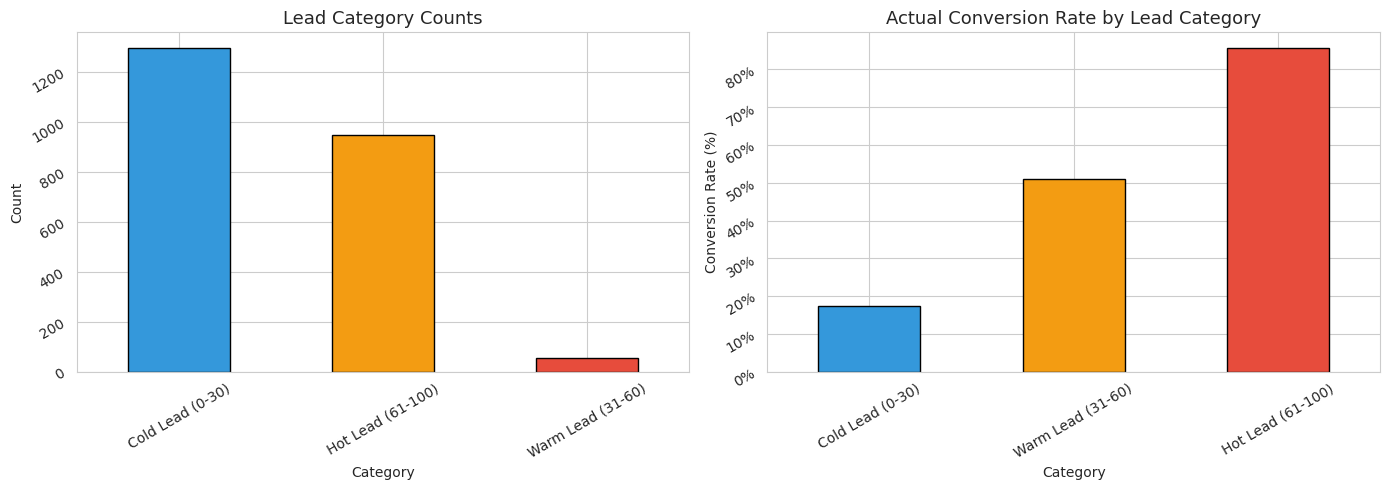

In [ ]:
# Lead category visualisation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count by category
test_results['Category'].value_counts().plot(kind='bar', ax=axes[0],
    color=['#3498DB', '#F39C12', '#E74C3C'], edgecolor='black')
axes[0].set_title('Lead Category Counts', fontsize=13)
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Count')
axes[0].tick_params(rotation=30)

# Actual conversion rate by category
conv_by_cat = test_results.groupby('Category')['Converted_Actual'].mean() * 100
conv_by_cat.plot(kind='bar', ax=axes[1],
    color=['#3498DB', '#F39C12', '#E74C3C'], edgecolor='black')
axes[1].set_title('Actual Conversion Rate by Lead Category', fontsize=13)
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Conversion Rate (%)')
axes[1].tick_params(rotation=30)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())

plt.tight_layout()
plt.show()

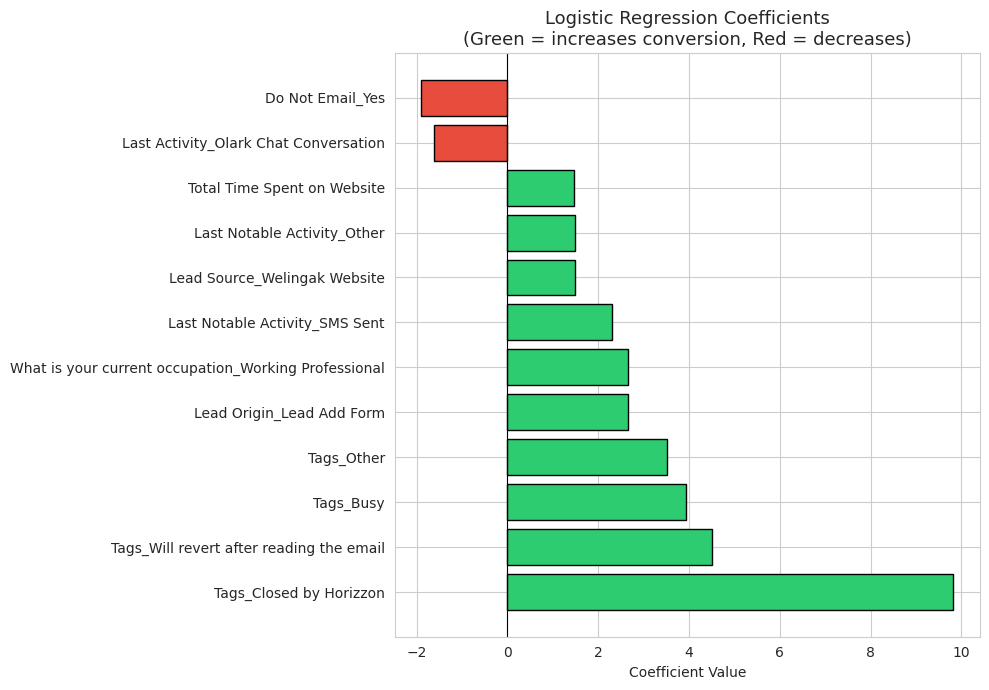


Top Positive Drivers (increase conversion probability):
                                             Feature  Coefficient
                             Tags_Closed by Horizzon     9.824980
            Tags_Will revert after reading the email     4.507693
                                           Tags_Busy     3.929904
                                          Tags_Other     3.511811
                           Lead Origin_Lead Add Form     2.661007
What is your current occupation_Working Professional     2.656738
                      Last Notable Activity_SMS Sent     2.303092
                        Lead Source_Welingak Website     1.499314
                         Last Notable Activity_Other     1.483646
                         Total Time Spent on Website     1.475043

Top Negative Drivers (decrease conversion probability):
                              Feature  Coefficient
Last Activity_Olark Chat Conversation    -1.626358
                     Do Not Email_Yes    -1.899931


In [ ]:
# ── 11.2 Feature Importance (Model Coefficients) ─────────────────
coef_df = pd.DataFrame({
    'Feature': final_features,
    'Coefficient': final_model.params[1:]   # skip constant
}).sort_values('Coefficient', ascending=False)

plt.figure(figsize=(10, 7))
colors = ['#2ECC71' if c > 0 else '#E74C3C' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors, edgecolor='black')
plt.axvline(x=0, color='black', linewidth=0.8)
plt.xlabel('Coefficient Value')
plt.title('Logistic Regression Coefficients\n(Green = increases conversion, Red = decreases)', fontsize=13)
plt.tight_layout()
plt.show()

print('\nTop Positive Drivers (increase conversion probability):')
print(coef_df[coef_df['Coefficient'] > 0][['Feature','Coefficient']].to_string(index=False))

print('\nTop Negative Drivers (decrease conversion probability):')
print(coef_df[coef_df['Coefficient'] < 0][['Feature','Coefficient']].to_string(index=False))

## Step 12: Business Questions (Company Problem Adjustments)

The company may ask the model to adjust for different scenarios. Below are the typical scenarios.

In [ ]:
# ── Scenario A: CEO wants ~80% sensitivity (lead conversion rate ~80%) ─
# Find the cutoff that gives sensitivity ≈ 0.80 on test set
fprs, tprs, cuts = roc_curve(y_test, y_test_pred_prob)

target_sensitivity = 0.80
closest_idx = np.argmin(np.abs(tprs - target_sensitivity))
cutoff_80 = cuts[closest_idx]

y_80 = (y_test_pred_prob >= cutoff_80).astype(int)
cm_80 = confusion_matrix(y_test, y_80)
tn80, fp80, fn80, tp80 = cm_80.ravel()

print(f'=== Scenario A: Target Sensitivity ~80% ===')
print(f'Optimal Cutoff : {cutoff_80:.3f}')
print(f'Sensitivity    : {tp80/(tp80+fn80)*100:.2f}%')
print(f'Specificity    : {tn80/(tn80+fp80)*100:.2f}%')
print(f'Accuracy       : {(tp80+tn80)/(tp80+tn80+fp80+fn80)*100:.2f}%')

=== Scenario A: Target Sensitivity ~80% ===
Optimal Cutoff : 0.383
Sensitivity    : 78.56%
Specificity    : 90.38%
Accuracy       : 85.82%


In [ ]:
# ── Scenario B: Lower lead volume but higher precision (busy sales period) ─
target_precision = 0.85
prec_vals, rec_vals, pr_cuts = precision_recall_curve(y_test, y_test_pred_prob)

closest_pr_idx = np.argmin(np.abs(prec_vals - target_precision))
cutoff_prec = pr_cuts[closest_pr_idx] if closest_pr_idx < len(pr_cuts) else pr_cuts[-1]

y_prec = (y_test_pred_prob >= cutoff_prec).astype(int)
cm_prec = confusion_matrix(y_test, y_prec)
tn_p, fp_p, fn_p, tp_p = cm_prec.ravel()

print(f'=== Scenario B: Target Precision ~85% (Busy Period) ===')
print(f'Optimal Cutoff : {cutoff_prec:.3f}')
print(f'Precision      : {tp_p/(tp_p+fp_p)*100:.2f}%')
print(f'Sensitivity    : {tp_p/(tp_p+fn_p)*100:.2f}%')
print(f'Accuracy       : {(tp_p+tn_p)/(tp_p+tn_p+fp_p+fn_p)*100:.2f}%')

=== Scenario B: Target Precision ~85% (Busy Period) ===
Optimal Cutoff : 0.404
Precision      : 84.90%
Sensitivity    : 76.87%
Accuracy       : 85.82%


In [ ]:
# ── Summary comparison of all scenarios ──────────────────────────
summary = pd.DataFrame({
    'Scenario': ['Default (0.50)', f'Optimal ({OPTIMAL_CUTOFF})', 'High Sensitivity (~80%)', 'High Precision (~85%)'],
    'Cutoff': [0.50, OPTIMAL_CUTOFF, round(cutoff_80, 3), round(cutoff_prec, 3)],
})
print(summary.to_string(index=False))

               Scenario  Cutoff
         Default (0.50)   0.500
          Optimal (0.3)   0.300
High Sensitivity (~80%)   0.383
  High Precision (~85%)   0.404


## Step 13: Export Final Results

In [ ]:
# Export test results with lead scores
test_results.to_csv('Lead_Scores_Output.csv', index=False)
print('Exported: Lead_Scores_Output.csv')

# Export model summary
with open('Model_Summary.txt', 'w') as f:
    f.write(str(final_model.summary2()))
print('Exported: Model_Summary.txt')

print('\n✅ All done! Your deliverables:')
print('  1. Lead_Scores_Output.csv  — Lead scores for all test leads')
print('  2. Model_Summary.txt       — Logistic regression coefficients & stats')
print('  3. This notebook           — Full analysis with visualisations')

Exported: Lead_Scores_Output.csv
Exported: Model_Summary.txt

✅ All done! Your deliverables:
  1. Lead_Scores_Output.csv  — Lead scores for all test leads
  2. Model_Summary.txt       — Logistic regression coefficients & stats
  3. This notebook           — Full analysis with visualisations


## Conclusion

**Key Findings:**
- The logistic regression model assigns every lead a score from 0 to 100. Leads scoring 61-100 are **Hot**, 31-60 are **Warm** and 0-30 are **Cold**.
- At the chosen cutoff of 0.30, the model reaches **85.79% accuracy, 78.56% sensitivity, 90.32% specificity and 83.57% precision** on the test set. Sensitivity is just under the CEO's ~80% target.
- On the test set, 948 of 2,772 leads (about 34%) were scored Hot.
- Top drivers that **increase** conversion: the tags *Closed by Horizzon*, *Will revert after reading the email* and *Busy*, leads from the **Lead Add Form**, **working professionals**, **SMS sent** as the last notable activity, the **Welingak Website** source and more **time spent on the website**.
- Drivers that **decrease** conversion: **Do Not Email = Yes** and **Olark Chat Conversation** as the last activity.

**Business Recommendation:**
- Focus sales calls first on Hot leads (score above 60) so the team spends its time on the leads most likely to convert.
- In busy periods, raise the cutoff to about 0.40 to reach roughly 85% precision (76.9% sensitivity), giving the team fewer but higher-quality leads.
- Prioritise lead sources and origins that convert well (Lead Add Form, Welingak Website) and follow up quickly with leads who said they will revert after reading the email.

**Limitation:** Tags are recorded by the sales team after they contact a lead, so they can carry information about the outcome. A model used to score brand-new leads should be rebuilt without them.
